# HR Analytics – Mitarbeiterfluktuation (IBM)

**Business-Frage:** Welche Mitarbeitergruppen kündigen überdurchschnittlich oft, und welche Faktoren hängen am stärksten mit der Fluktuation zusammen?

Datensatz: IBM HR Analytics Employee Attrition (Kaggle), 1.470 Mitarbeiter, 35 Merkmale.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
IMG = '../images/'

df = pd.read_csv('../data/hr_employee_attrition.csv', encoding='utf-8-sig')
print(f'Dataset size: {df.shape}')
df.head()

Dataset size: (1470, 35)


,Age,Attrition,BusinessTravel,DailyRate,Department,DistanceFromHome,Education,EducationField,EmployeeCount,EmployeeNumber,...,RelationshipSatisfaction,StandardHours,StockOptionLevel,TotalWorkingYears,TrainingTimesLastYear,WorkLifeBalance,YearsAtCompany,YearsInCurrentRole,YearsSinceLastPromotion,YearsWithCurrManager
0,41,Yes,Travel_Rarely,1102,Sales,1,2,Life Sciences,1,1,...,1,80,0,8,0,1,6,4,0,5
1,49,No,Travel_Frequently,279,Research & Development,8,1,Life Sciences,1,2,...,4,80,1,10,3,3,10,7,1,7
2,37,Yes,Travel_Rarely,1373,Research & Development,2,2,Other,1,4,...,2,80,0,7,3,3,0,0,0,0
3,33,No,Travel_Frequently,1392,Research & Development,3,4,Life Sciences,1,5,...,3,80,0,8,3,3,8,7,3,0
4,27,No,Travel_Rarely,591,Research & Development,2,1,Medical,1,7,...,4,80,1,6,3,3,2,2,2,2


## 1. Datenprüfung und Bereinigung

In [2]:
print('=== Missing values (total) ===')
print(df.isnull().sum().sum())
print('\n=== Duplicate rows ===')
print(df.duplicated().sum())

# Columns with only one value carry no information
constant_cols = [c for c in df.columns if df[c].nunique() == 1]
print(f'\nConstant columns: {constant_cols}')

=== Missing values (total) ===
0

=== Duplicate rows ===
0

Constant columns: ['EmployeeCount', 'Over18', 'StandardHours']


In [3]:
df = df.drop(columns=constant_cols + ['EmployeeNumber'])
df['Left'] = (df['Attrition'] == 'Yes').astype(int)
print(f'Columns after cleaning: {df.shape[1] - 1}')
df.describe().T

Columns after cleaning: 31


,count,mean,std,min,25%,50%,75%,max
Age,1470.0,36.923810,9.135373,18.0,30.0,36.0,43.00,60.0
DailyRate,1470.0,802.485714,403.509100,102.0,465.0,802.0,1157.00,1499.0
DistanceFromHome,1470.0,9.192517,8.106864,1.0,2.0,7.0,14.00,29.0
Education,1470.0,2.912925,1.024165,1.0,2.0,3.0,4.00,5.0
EnvironmentSatisfaction,1470.0,2.721769,1.093082,1.0,2.0,3.0,4.00,4.0
HourlyRate,1470.0,65.891156,20.329428,30.0,48.0,66.0,83.75,100.0
JobInvolvement,1470.0,2.729932,0.711561,1.0,2.0,3.0,3.00,4.0
JobLevel,1470.0,2.063946,1.106940,1.0,1.0,2.0,3.00,5.0
JobSatisfaction,1470.0,2.728571,1.102846,1.0,2.0,3.0,4.00,4.0
MonthlyIncome,1470.0,6502.931293,4707.956783,1009.0,2911.0,4919.0,8379.00,19999.0


## 2. Gesamt-Fluktuationsrate

In [4]:
overall = df['Left'].mean() * 100
print(f'Attrition rate: {overall:.1f} % ({df["Left"].sum()} of {len(df)} employees)')

Attrition rate: 16.1 % (237 of 1470 employees)


## 3. Fluktuationsrate nach Gruppen

Verglichen werden **Raten** (Anteil Kündigungen pro Gruppe), nicht absolute Zahlen – sonst wirken große Abteilungen automatisch auffälliger.

In [5]:
def rate(col):
    t = df.groupby(col, observed=True)['Left'].agg(['mean', 'size'])
    t.columns = ['Attrition %', 'Employees']
    t['Attrition %'] = (t['Attrition %'] * 100).round(1)
    return t.sort_values('Attrition %', ascending=False)

df['AgeGroup'] = pd.cut(df['Age'], bins=[17, 30, 40, 50, 60], labels=['18–30', '31–40', '41–50', '51–60'])

for col in ['OverTime', 'Department', 'AgeGroup', 'MaritalStatus', 'BusinessTravel', 'JobLevel']:
    print(f'=== {col} ===')
    print(rate(col), '\n')

=== OverTime ===
          Attrition %  Employees
OverTime                        
Yes              30.5        416
No               10.4       1054 

=== Department ===
                        Attrition %  Employees
Department                                    
Sales                          20.6        446
Human Resources                19.0         63
Research & Development         13.8        961 

=== AgeGroup ===
          Attrition %  Employees
AgeGroup                        
18–30            25.9        386
31–40            13.7        619
51–60            12.6        143
41–50            10.6        322 

=== MaritalStatus ===
               Attrition %  Employees
MaritalStatus                        
Single                25.5        470
Married               12.5        673
Divorced              10.1        327 

=== BusinessTravel ===
                   Attrition %  Employees
BusinessTravel                           
Travel_Frequently         24.9        277
Travel_Rarely

In [6]:
print('=== JobRole ===')
print(rate('JobRole'))

=== JobRole ===
                           Attrition %  Employees
JobRole                                          
Sales Representative              39.8         83
Laboratory Technician             23.9        259
Human Resources                   23.1         52
Sales Executive                   17.5        326
Research Scientist                16.1        292
Healthcare Representative          6.9        131
Manufacturing Director             6.9        145
Manager                            4.9        102
Research Director                  2.5         80


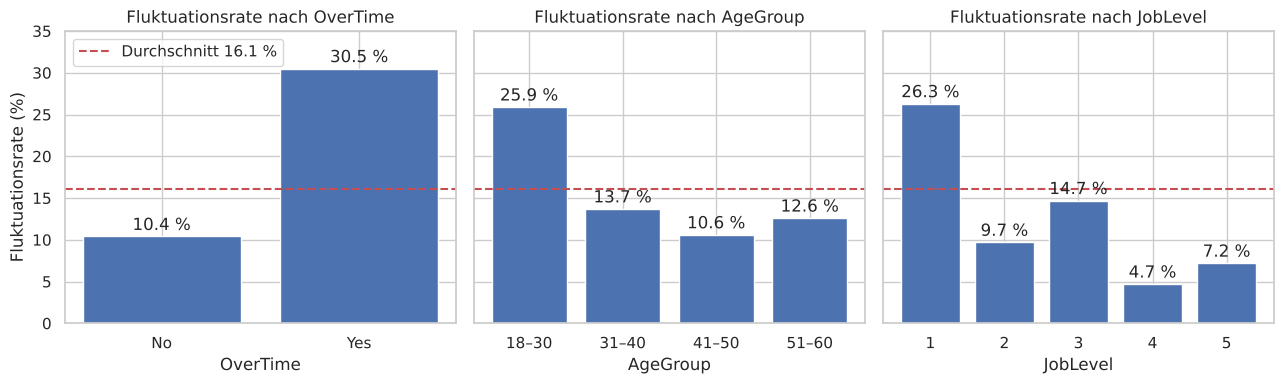

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4), sharey=True)
for ax, col in zip(axes, ['OverTime', 'AgeGroup', 'JobLevel']):
    r = rate(col).sort_index()
    ax.bar(r.index.astype(str), r['Attrition %'], color='#4C72B0')
    ax.axhline(overall, color='#C44E52', linestyle='--', label=f'Durchschnitt {overall:.1f} %')
    for i, v in enumerate(r['Attrition %']):
        ax.text(i, v + 0.3, f'{v:.1f} %', ha='center', va='bottom')
    ax.set_ylim(0, 35)
    ax.set_title(f'Fluktuationsrate nach {col}')
    ax.set_xlabel(col)
axes[0].set_ylabel('Fluktuationsrate (%)')
axes[0].legend()
plt.tight_layout()
plt.savefig(IMG + 'attrition_by_group.png', dpi=150)
plt.show()

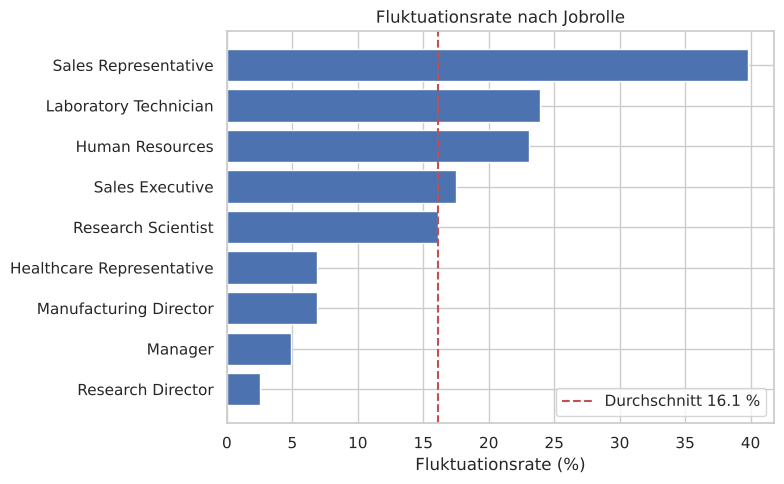

In [8]:
roles = rate('JobRole').sort_values('Attrition %')
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(roles.index, roles['Attrition %'], color='#4C72B0')
ax.axvline(overall, color='#C44E52', linestyle='--', label=f'Durchschnitt {overall:.1f} %')
ax.set_title('Fluktuationsrate nach Jobrolle')
ax.set_xlabel('Fluktuationsrate (%)')
ax.legend()
plt.tight_layout()
plt.savefig(IMG + 'attrition_by_jobrole.png', dpi=150)
plt.show()

## 4. Gehalt und Fluktuation

In [9]:
income = df.groupby('Attrition')['MonthlyIncome'].agg(['median', 'mean']).round(0)
print(income)
diff = 1 - income.loc['Yes', 'median'] / income.loc['No', 'median']
print(f'\nEmployees who left earn {diff:.0%} less (median) than those who stayed')

           median    mean
Attrition                
No         5204.0  6833.0
Yes        3202.0  4787.0

Employees who left earn 38% less (median) than those who stayed


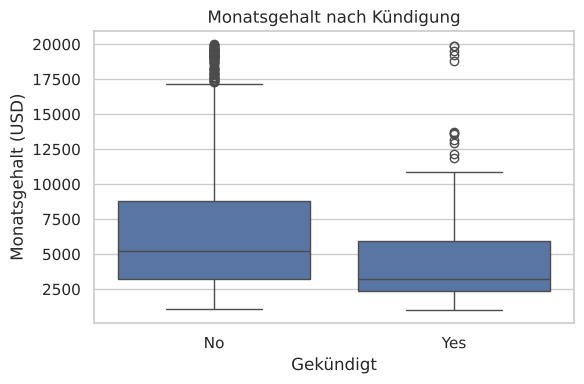

In [10]:
fig, ax = plt.subplots(figsize=(6, 4))
sns.boxplot(data=df, x='Attrition', y='MonthlyIncome', order=['No', 'Yes'], ax=ax)
ax.set_title('Monatsgehalt nach Kündigung')
ax.set_xlabel('Gekündigt')
ax.set_ylabel('Monatsgehalt (USD)')
plt.tight_layout()
plt.show()

## 5. Korrelationen zwischen numerischen Merkmalen

TotalWorkingYears         -0.17
JobLevel                  -0.17
MonthlyIncome             -0.16
Age                       -0.16
YearsAtCompany            -0.13
JobSatisfaction           -0.10
WorkLifeBalance           -0.06
YearsSinceLastPromotion   -0.03
DistanceFromHome           0.08
Name: Left, dtype: float64


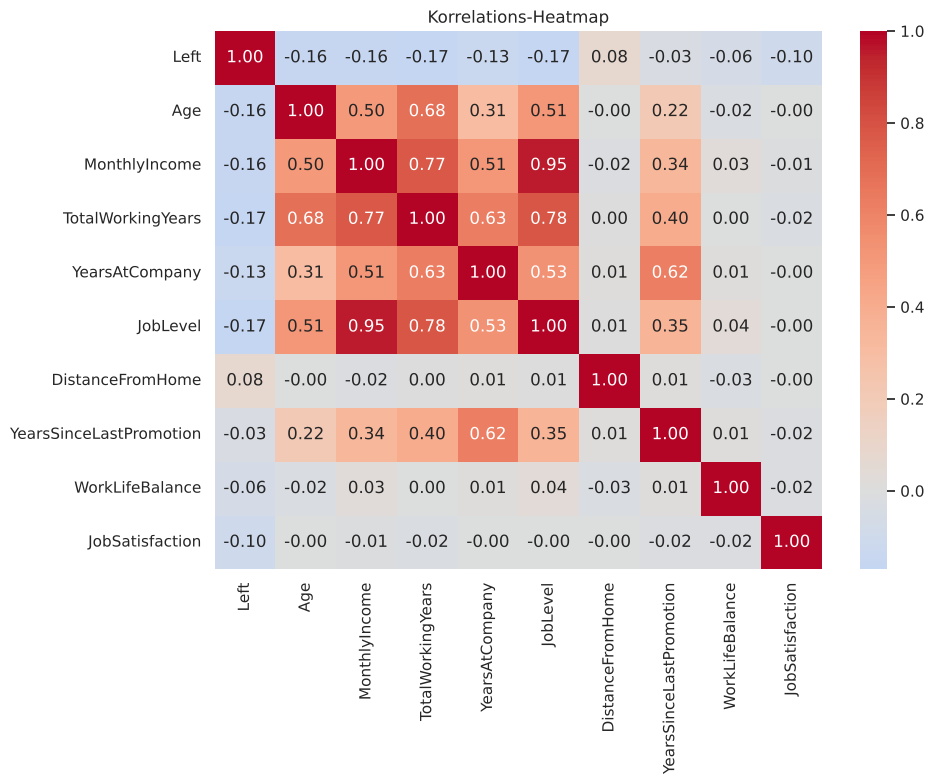

In [11]:
cols = ['Left', 'Age', 'MonthlyIncome', 'TotalWorkingYears', 'YearsAtCompany',
        'JobLevel', 'DistanceFromHome', 'YearsSinceLastPromotion', 'WorkLifeBalance', 'JobSatisfaction']
corr = df[cols].corr()
print(corr['Left'].drop('Left').sort_values().round(2))

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Korrelations-Heatmap')
plt.tight_layout()
plt.show()

## 6. Logistische Regression – welche Faktoren erklären die Kündigung?

Einfaches Modell zur Einordnung der Einflussfaktoren (kein Produktivmodell).

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import roc_auc_score

X = pd.get_dummies(df.drop(columns=['Attrition', 'Left', 'AgeGroup']), drop_first=True).astype(float)
y = df['Left']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
model = LogisticRegression(max_iter=2000, class_weight='balanced')
model.fit(scaler.fit_transform(X_train), y_train)

auc = roc_auc_score(y_test, model.predict_proba(scaler.transform(X_test))[:, 1])
print(f'ROC-AUC on test set: {auc:.2f}')

coefs = pd.Series(model.coef_[0], index=X.columns).sort_values()
print('\nStrongest factors increasing attrition:')
print(coefs.tail(5).round(2))
print('\nStrongest factors decreasing attrition:')
print(coefs.head(5).round(2))

ROC-AUC on test set: 0.81

Strongest factors increasing attrition:
JobRole_Sales Representative        0.56
BusinessTravel_Travel_Frequently    0.70
JobLevel                            0.71
OverTime_Yes                        0.78
JobRole_Laboratory Technician       0.86
dtype: float64

Strongest factors decreasing attrition:
TotalWorkingYears              -0.56
EducationField_Life Sciences   -0.53
YearsWithCurrManager           -0.48
EducationField_Medical         -0.43
EnvironmentSatisfaction        -0.43
dtype: float64


## 7. Fazit und Handlungsempfehlungen

1. **Überstunden reduzieren:** Mitarbeiter mit Überstunden kündigen fast dreimal so häufig. Überstunden sollten regelmäßig überwacht und ausgeglichen werden.
2. **Einstiegsebene und junge Mitarbeiter binden:** Job-Level 1 und die Altersgruppe 18–30 haben die höchsten Raten – Onboarding, Mentoring und klare Entwicklungspfade.
3. **Sales Representatives:** Die Rolle mit der höchsten Fluktuation – Vergütung und Arbeitsbedingungen gezielt prüfen.
4. **Vergütung:** Gekündigte verdienen im Median deutlich weniger – Gehaltsbänder in den unteren Stufen überprüfen.

Alle Zahlen stammen aus den Ausgaben der Zellen oben.